# Qiskit Fall Fest 2026
## Challenge 3: Change the Relationship Between Two Qubits

**Objective:** Create a Bell-state circuit, modify one quantum gate, and compare the measurement outcomes of the original and modified circuits.

In [1]:
from qiskit import QuantumCircuit
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram
import matplotlib.pyplot as plt

simulator = AerSimulator()

## Theory and Prediction

A Bell state is an entangled state involving two qubits.

The original circuit uses an H gate followed by a CNOT gate.

**Original circuit prediction:**
- 00: approximately 50%
- 11: approximately 50%
- 01 and 10: 0% ideally

For the modified circuit, I will add an X gate to qubit 0.

The X gate flips qubit 0, changing the matching outcomes into opposite outcomes.

**Modified circuit prediction:**
- 01: approximately 50%
- 10: approximately 50%
- 00 and 11: 0% ideally

Original Bell-State Circuit


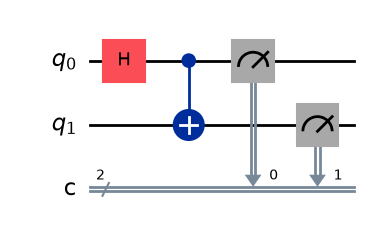

Original circuit results: {'00': 57, '11': 43}


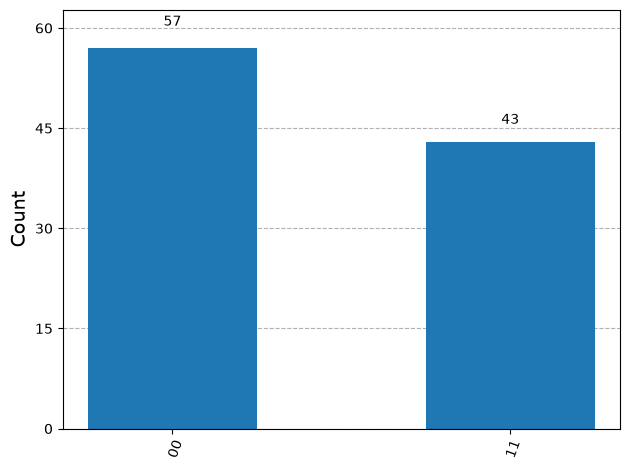

In [11]:
original = QuantumCircuit(2, 2)

original.h(0)
original.cx(0, 1)

original.measure(0, 0)
original.measure(1, 1)

print("Original Bell-State Circuit")
display(original.draw("mpl"))

result_original = simulator.run(
    original, shots=100
).result()

counts_original = result_original.get_counts()

print("Original circuit results:", counts_original)

fig = plot_histogram(counts_original)
display(fig)
plt.close(fig)

Modified Bell-State Circuit


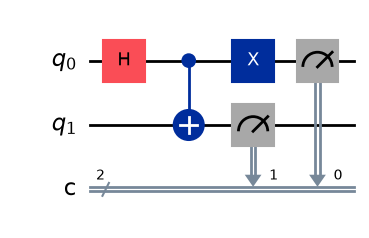

Modified circuit results: {'01': 48, '10': 52}


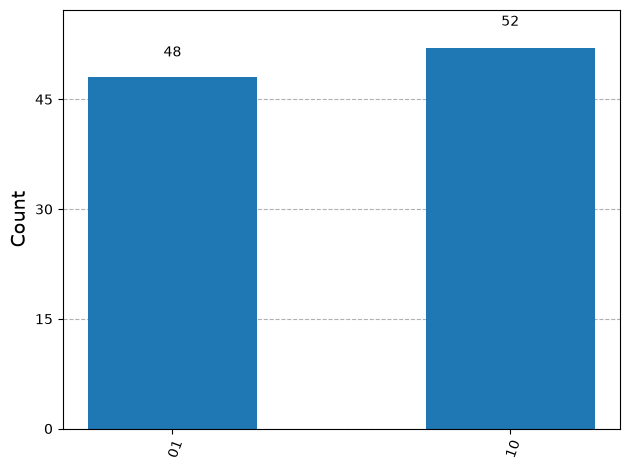

In [14]:
modified = QuantumCircuit(2, 2)

modified.h(0)
modified.cx(0, 1)

# Added gate: flip qubit 0
modified.x(0) 

modified.measure(0, 0)
modified.measure(1, 1)

print("Modified Bell-State Circuit")
display(modified.draw("mpl"))

result_modified = simulator.run(
    modified, shots=100
).result()

counts_modified = result_modified.get_counts()

print("Modified circuit results:", counts_modified)

fig = plot_histogram(counts_modified)
display(fig)
plt.close(fig)

ORIGINAL CIRCUIT
{'00': 57, '11': 43}

MODIFIED CIRCUIT
{'01': 48, '10': 52}


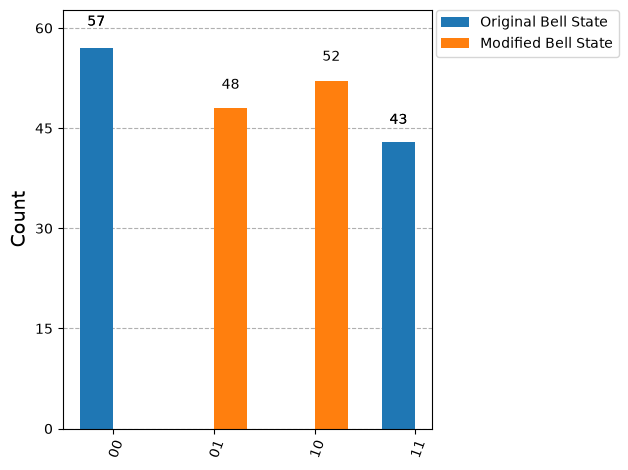

In [15]:
print("ORIGINAL CIRCUIT")
print(counts_original)

print("\nMODIFIED CIRCUIT")
print(counts_modified)

fig = plot_histogram(
    [counts_original, counts_modified],
    legend=["Original Bell State", "Modified Bell State"]
)

display(fig)
plt.close(fig)

## Comparison and Observation

The original Bell-state circuit produced correlated outcomes. Both qubits had the same measurement result, giving 00 or 11.

I modified the circuit by adding an X gate to qubit 0 after the CNOT gate.

The X gate flipped qubit 0, changing the possible outcomes from 00 and 11 to 01 and 10.

The modified circuit therefore produced opposite measurement results. The results demonstrate how adding a single quantum gate can change the relationship between two entangled qubits.

The actual counts may vary slightly because the circuits are executed for 100 shots.